# 05 — Model Evaluation

Evaluate the frozen model and threshold on train, validation and test. Compare with a majority-class baseline and an untuned Logistic Regression. Test results are saved and reused for the same model and splits; they are not used to tune the model.

In [1]:
from pathlib import Path
import sys
import json
import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
MODEL_DIR = PROJECT_ROOT / "models"
pd.set_option("display.max_columns", None)

In [2]:
from src.modeling.evaluate import evaluate_model
results, evaluation = evaluate_model()
display(results.round(4))

,model,split,rows,positive_count,threshold,pr_auc,roc_auc,accuracy,balanced_accuracy,precision,recall,f1,tn,fp,fn,tp
0,selected_model,train,3577,174,0.4021,0.5504,0.9626,0.7640,0.8760,0.1709,1.0000,0.2919,2559,844,0,174
1,selected_model,validation,766,37,0.4021,0.2680,0.8501,0.7546,0.7941,0.1455,0.8378,0.2480,547,182,6,31
2,selected_model,test,767,38,0.4021,0.2226,0.8224,0.7314,0.7589,0.1316,0.7895,0.2256,531,198,8,30
3,dummy_prior,train,3577,174,0.5000,0.0486,0.5000,0.9514,0.5000,0.0000,0.0000,0.0000,3403,0,174,0
4,dummy_prior,validation,766,37,0.5000,0.0483,0.5000,0.9517,0.5000,0.0000,0.0000,0.0000,729,0,37,0
5,dummy_prior,test,767,38,0.5000,0.0495,0.5000,0.9505,0.5000,0.0000,0.0000,0.0000,729,0,38,0
6,baseline_logistic,train,3577,174,0.5000,0.2132,0.8639,0.7585,0.7940,0.1480,0.8333,0.2513,2568,835,29,145
7,baseline_logistic,validation,766,37,0.5000,0.2742,0.8518,0.7454,0.7380,0.1274,0.7297,0.2169,544,185,10,27
8,baseline_logistic,test,767,38,0.5000,0.2355,0.8361,0.7419,0.7769,0.1396,0.8158,0.2385,538,191,7,31


In [3]:
selected = results[results["model"] == "selected_model"].set_index("split")
display(selected[["pr_auc", "roc_auc", "accuracy", "precision", "recall", "f1", "tn", "fp", "fn", "tp"]].round(4))
print("Train minus validation PR-AUC:", round(selected.loc["train", "pr_auc"] - selected.loc["validation", "pr_auc"], 4))
print("Training scores are in-sample; CV and holdout scores assess generalization.")
print("Validation was used to select the threshold, so threshold-dependent validation metrics are optimistic.")
print("No model or threshold changes are made from the test results.")

,pr_auc,roc_auc,accuracy,precision,recall,f1,tn,fp,fn,tp
split,,,,,,,,,,
train,0.5504,0.9626,0.7640,0.1709,1.0000,0.2919,2559,844,0,174
validation,0.2680,0.8501,0.7546,0.1455,0.8378,0.2480,547,182,6,31
test,0.2226,0.8224,0.7314,0.1316,0.7895,0.2256,531,198,8,30


Train minus validation PR-AUC: 0.2824
Training scores are in-sample; CV and holdout scores assess generalization.
Validation was used to select the threshold, so threshold-dependent validation metrics are optimistic.
No model or threshold changes are made from the test results.


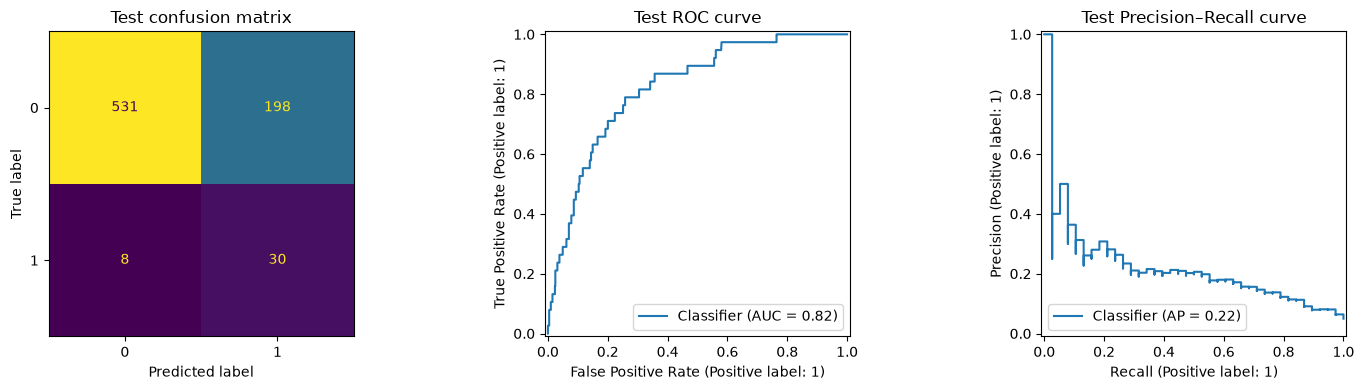

In [4]:
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay
predictions = pd.read_csv(MODEL_DIR / "test_predictions.csv")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay.from_predictions(predictions["stroke"], predictions["prediction"], ax=axes[0], colorbar=False)
axes[0].set_title("Test confusion matrix")
RocCurveDisplay.from_predictions(predictions["stroke"], predictions["model_score"], ax=axes[1])
axes[1].set_title("Test ROC curve")
PrecisionRecallDisplay.from_predictions(predictions["stroke"], predictions["model_score"], ax=axes[2])
axes[2].set_title("Test Precision–Recall curve")
plt.tight_layout()
plt.show()

In [5]:
from src.modeling.export import export_browser_model
browser_model = export_browser_model()
print("Browser model:", browser_model["model_name"])
print("Inputs:", browser_model["required_raw_features"])

Exported random_forest to C:\Users\Asus\Organized\02_Study_and_University\Year 2 Semester 1\MachineLearning\Final\stroke-prediction\web\model.json
Browser model: random_forest
Inputs: ['age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'avg_glucose_level', 'bmi']


## Observations

The selected Random Forest has much higher training AP than validation AP, indicating overfitting. Validation and test AP are above the dummy baseline, but the untuned Logistic Regression has slightly better test AP. The recall target was chosen on validation and is not guaranteed on test. Precision is low, so this remains a classroom prototype. No model changes are made after reviewing test results.